In [2]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_2, MUDO     = "#52514e", "#898781"
GRADE, EIXO       = "#e1e0d9", "#c3c2b7"
REAL, PREDITO     = "#2a78d6", "#eb6834"   # slots categoricos 1 e 2
ERRO_CLARO, MAE_ESC = "#86b6ef", "#184f95" # rampa azul: degraus 250 e 600

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"],
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
})



SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios


DATA_DIR = Path.cwd().parent / "data" / "processed"

print(f"dados em {DATA_DIR}")
print(f"semente: {SEED}")

dados em c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\processed
semente: 42


In [3]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpee1*.csv"))
)
CAMINHOS = {p.stem: p for p in ARQUIVOS}   # para reconferir contra o CSV bruto no fim
print(f"{len(ARQUIVOS)} arquivos" + NL)

def enfeitar(ax, titulo, xlabel, ylabel):
        ax.set_title(titulo, color=TINTA, fontsize=12, loc="left", pad=10)
        ax.set_xlabel(xlabel, color=TINTA_2, fontsize=10)
        ax.set_ylabel(ylabel, color=TINTA_2, fontsize=10)
        ax.grid(True, color=GRADE, linewidth=0.6, linestyle="-")
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        for lado in ("left", "bottom"):
            ax.spines[lado].set_color(EIXO)
        ax.tick_params(colors=MUDO, labelsize=9)

def load_file(p: Path):
    df = pd.read_csv(p, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    df["datetime"] = pd.to_datetime(df["datetime"])
    return df

partes = []
for p in ARQUIVOS:
    df = load_file(p)
    df['station'] = p.stem
    partes.append(df)
    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

def show_dataset(dataset: pd.DataFrame):
    # A ordem das colunas difere entre os schemas; a uniao e por nome.
    print(NL + f"pool: {len(dataset)} linhas, {dataset.shape[1]} colunas")
    print(NL + "nulos por coluna (so as que tem):")
    nulos = dataset.isna().sum()
    print(nulos[nulos > 0].to_string() if (nulos > 0).any() else "  (nenhum)")
    print(NL + "colunas com zero:")
    zeros = dataset.isin([0]).sum()
    print(zeros[zeros > 0].to_string() if (zeros > 0).any() else "  (nenhum)")
    return dataset
    


raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

1 arquivos

  processed  ifpee1             16653 linhas  19 colunas


In [4]:

# remover colunas "mortas"
REMOVE_COLS = {"arquivo", "estacao", "ano"}
if REMOVE_COLS.issubset(raw.columns):
    raw = raw.drop(columns=[c for c in REMOVE_COLS if c in raw.columns])

df = show_dataset(raw.copy())


pool: 16653 linhas, 19 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA            256
ghit             8
sintetico    16369


In [5]:
d2 = df.assign(
    hora=df.datetime.dt.hour,
    mes=df.datetime.dt.month,
)

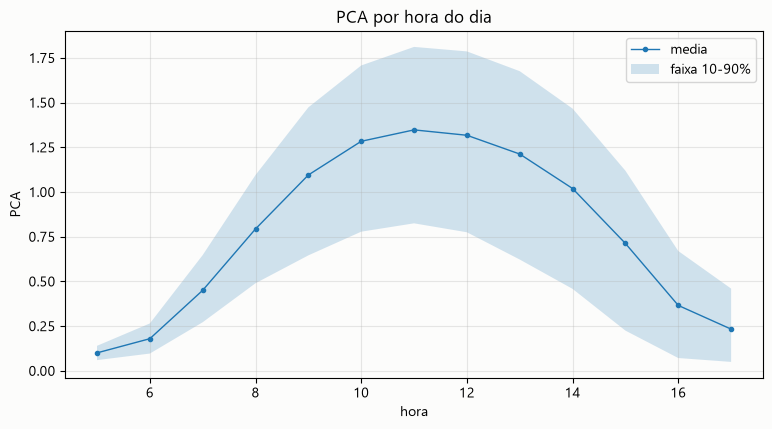

In [6]:

# 1) curva diaria de PCA
g = d2.groupby("hora")["PCA"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(g.mean().index, g.mean().values, marker=".", lw=1, label="media")
ax.fill_between(g.mean().index, g.quantile(0.1).values, g.quantile(0.9).values,
                alpha=0.2, label="faixa 10-90%")
ax.set_title("PCA por hora do dia"); ax.set_xlabel("hora"); ax.set_ylabel("PCA")
ax.grid(alpha=0.3); ax.legend()

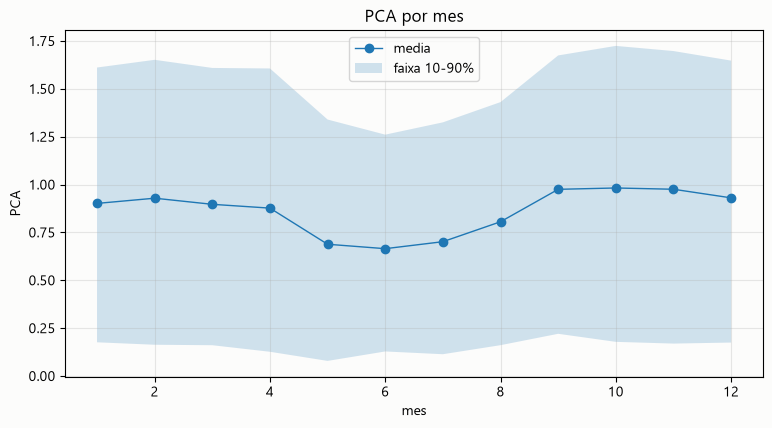

In [7]:

# 2) curva anual
gm = d2.groupby("mes")["PCA"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(gm.mean().index, gm.mean().values, marker="o", lw=1, label="media")
ax.fill_between(gm.mean().index, gm.quantile(0.1).values, gm.quantile(0.9).values,
                alpha=0.2, label="faixa 10-90%")
ax.set_title("PCA por mes"); ax.set_xlabel("mes"); ax.set_ylabel("PCA")
ax.grid(alpha=0.3); ax.legend()


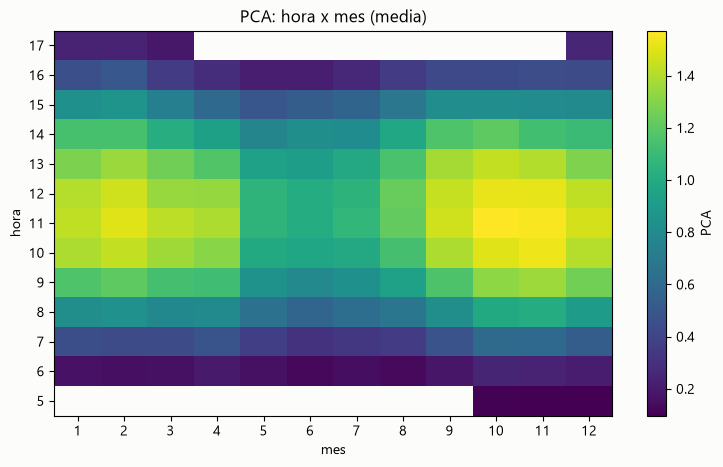

In [8]:

# 3) heatmap hora x mes
tab = d2.pivot_table(index="hora", columns="mes", values="PCA", aggfunc="mean")
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(tab.to_numpy(), aspect="auto", origin="lower", cmap="viridis")
ax.set_title("PCA: hora x mes (media)")
ax.set_xlabel("mes"); ax.set_ylabel("hora")
ax.set_xticks(range(len(tab.columns)), tab.columns)
ax.set_yticks(range(len(tab.index)), tab.index)
plt.colorbar(im, ax=ax, label="PCA")

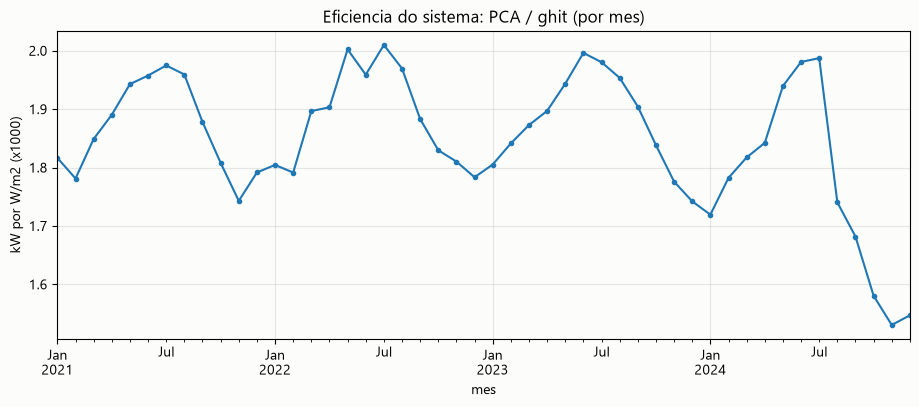

In [9]:
# 6) Estado do sistema ao longo do tempo: PCA gerado por W/m2 de sol.
#
# Nessa razao a sazonalidade some sozinha -- sol fraco gera pouco dos dois lados
# ao mesmo tempo -- entao o que sobra no grafico e' o estado do sistema.
# A perda a partir de ago/2024 aparece aqui: 13,9% contra a media de 2021-2023.
#
# Usa df (valores BRUTOS). Nao usar treino/teste: aqueles ja foram normalizados.
#
# Por que nao MSTL/STL: a serie tem 4 anos e STL(period=365) precisa de varias
# repeticoes do ciclo. Nesta janela a tendencia consumiria 697 dos 727 dias numa
# unica passada e o residuo sai identico a zero -- o "sazonal" engole tudo,
# inclusive a tendencia. Alem disso a serie horaria nao tem a noite (54% dos
# pontos) e preencher com interpolate() inventaria 18.863 valores de ghit.
d2 = df[df.PCA != 0]
ef = d2.groupby(d2["datetime"].dt.to_period("M")).apply(
    lambda g: g["PCA"].mean() / g["ghit"].mean()
)

fig, ax = plt.subplots(figsize=(11, 4))
(ef * 1000).plot(ax=ax, marker=".")
ax.set_title("Eficiencia do sistema: PCA / ghit (por mes)")
ax.set_xlabel("mes"); ax.set_ylabel("kW por W/m2 (x1000)"); ax.grid(alpha=.3)

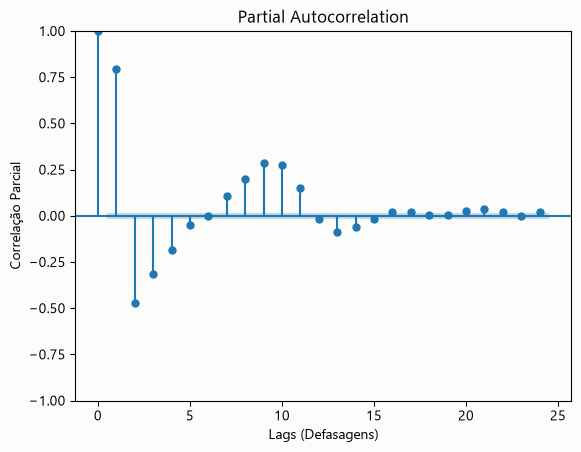

In [10]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(df[df.datetime.dt.year < 2024].PCA, lags=24, method="ywm")

# 3. Exibindo o gráfico
plt.xlabel("Lags (Defasagens)")
plt.ylabel("Correlação Parcial")
plt.show()

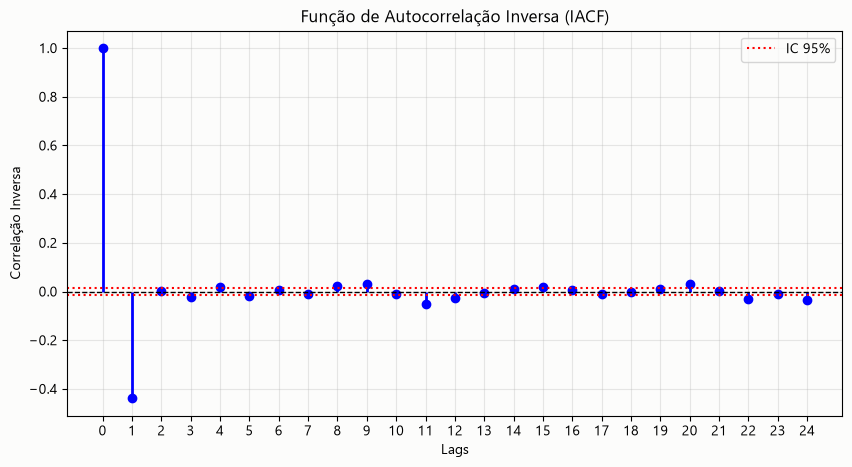

In [11]:
from statsmodels.regression.linear_model import yule_walker

def plot_iacf(series, lags=20):
    """
    Calcula e plota a Função de Autocorrelação Inversa (IACF)
    baseada na aproximação por um modelo autorregressivo de alta ordem.
    """
    # Remove valores nulos caso existam na série do Pandas
    series = series.dropna()
    n = len(series)
    
    # 1. Ajusta um modelo AR de alta ordem (Yule-Walker)
    # Geralmente usa-se a ordem sugerida pela metade das observações ou um limite prático
    ar_order = min(lags * 2, n // 3)
    ar_coefs, _ = yule_walker(series, order=ar_order, demean=True)
    
    # 2. Convoluciona os coeficientes AR com eles mesmos para obter a IACF aproximada
    # Adiciona 1 no início para representar o lag 0
    ar_operator = np.r_[1, -ar_coefs]
    iacf_raw = np.correlate(ar_operator, ar_operator, mode='full')
    
    # Pega apenas a metade positiva (lags de 0 em diante)
    iacf = iacf_raw[len(iacf_raw)//2 : len(iacf_raw)//2 + lags + 1]
    
    # Normaliza para que o lag 0 seja igual a 1
    iacf = iacf / iacf[0]

    # Remove lags muito baixos para evitar ruído visual (opcional)
    # iacf = np.where(np.abs(iacf) < 0.1, 0, iacf)
    
    # 3. Monta o gráfico no estilo clássico do statsmodels
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plota as barras verticais para os lags de 1 até o limite definido
    x_lags = np.arange(len(iacf))
    ax.vlines(x_lags, 0, iacf, colors='b', lw=2)
    ax.plot(x_lags, iacf, 'bo')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    # Limites de significância estatística aproximados (IC de 95%)
    conf_level = 1.96 / np.sqrt(n)
    ax.axhline(conf_level, color='red', linestyle=':', label='IC 95%')
    ax.axhline(-conf_level, color='red', linestyle=':')
    
    ax.set_title("Função de Autocorrelação Inversa (IACF)")
    ax.set_xlabel("Lags")
    ax.set_ylabel("Correlação Inversa")
    ax.set_xticks(x_lags)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_iacf(df.PCA, lags=24)


O valor ideal de Lambda (λ) encontrado foi: 0.6568


C:\Users\gusta\AppData\Local\Temp\ipykernel_14740\3286598770.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


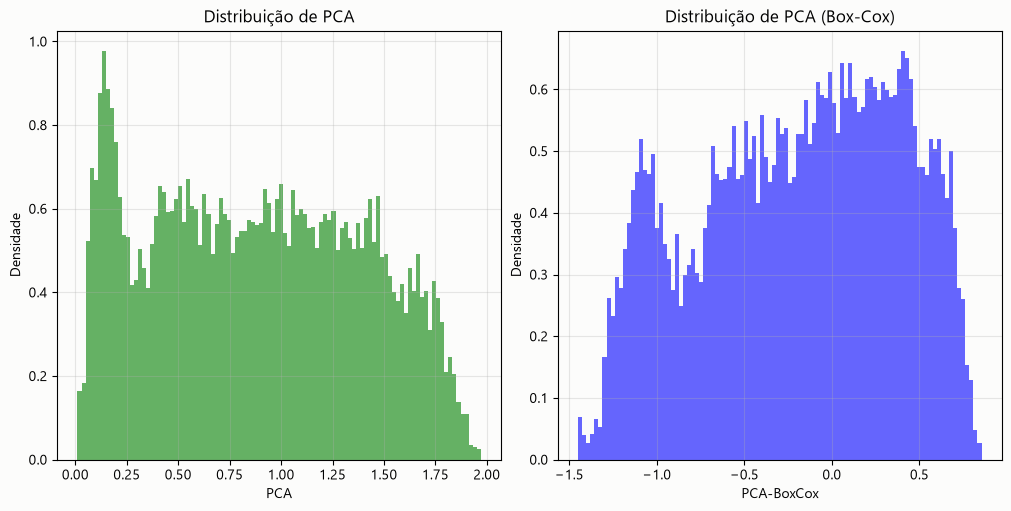

In [27]:
from scipy import stats

d = df[df.PCA != 0].copy().reset_index(drop=True)
d['PCA-BoxCox'], lmbda = stats.boxcox(d['PCA'])  # Adiciona um pequeno valor para evitar log(0)

print(f"\nO valor ideal de Lambda (λ) encontrado foi: {lmbda:.4f}")

fig, ax = plt.subplots(figsize=(10, 5), ncols=2, constrained_layout=True)
ax[0].hist(d['PCA'], bins=100, density=True, alpha=0.6, color='g')
ax[0].set_title("Distribuição de PCA")
ax[0].set_xlabel("PCA")
ax[0].set_ylabel("Densidade")
ax[0].grid(alpha=0.3)

# Plot the Box-Cox transformed data
ax[1].hist(d['PCA-BoxCox'], bins=100, density=True, alpha=0.6, color='b')
ax[1].set_title("Distribuição de PCA (Box-Cox)")
ax[1].set_xlabel("PCA-BoxCox")
ax[1].set_ylabel("Densidade")
ax[1].grid(alpha=0.3)

fig.show()

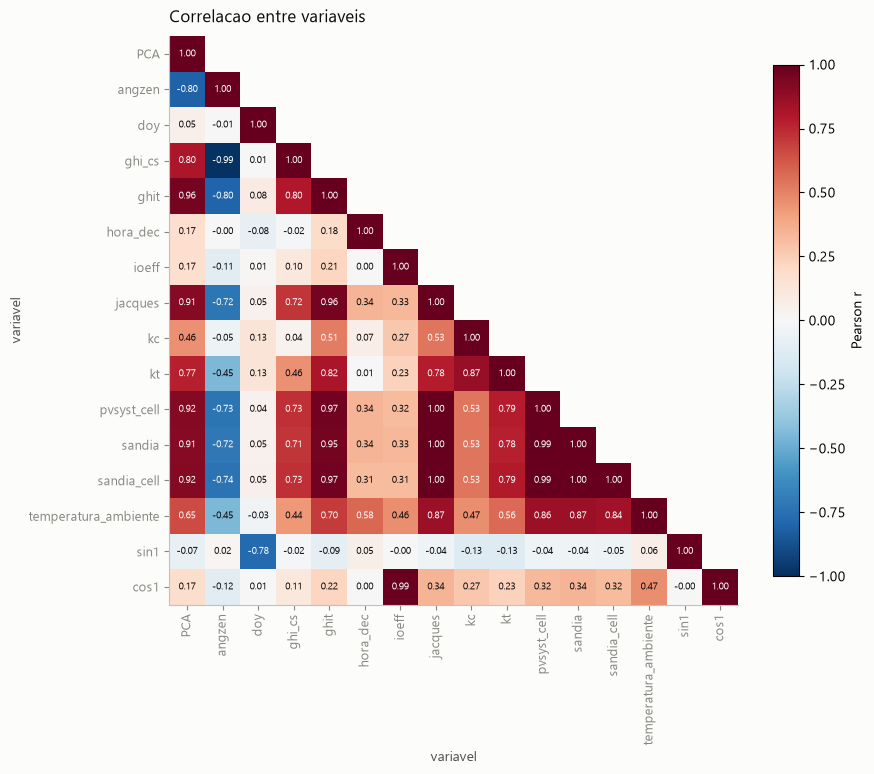

In [14]:
# Correlation matrix
corr_matrix = df.select_dtypes(include=[np.number]).corr()
# heatmap da matriz de correlacao (so o triangulo inferior; a matriz e' simetrica)
n = len(corr_matrix)
mask = np.triu(np.ones((n, n), dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_matrix.mask(mask).to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(n), corr_matrix.columns, rotation=90)
ax.set_yticks(range(n), corr_matrix.index)
ax.set_aspect("equal")
enfeitar(ax, "Correlacao entre variaveis", "variavel", "variavel")
ax.grid(False)

# anota o valor de Pearson dentro de cada celula
for r in range(n):
  for c in range(n):
    if c <= r:
      v = corr_matrix.iloc[r, c]
      ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
          color=SUPERFICIE if abs(v) > 0.5 else TINTA)

plt.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
plt.tight_layout()
plt.show()

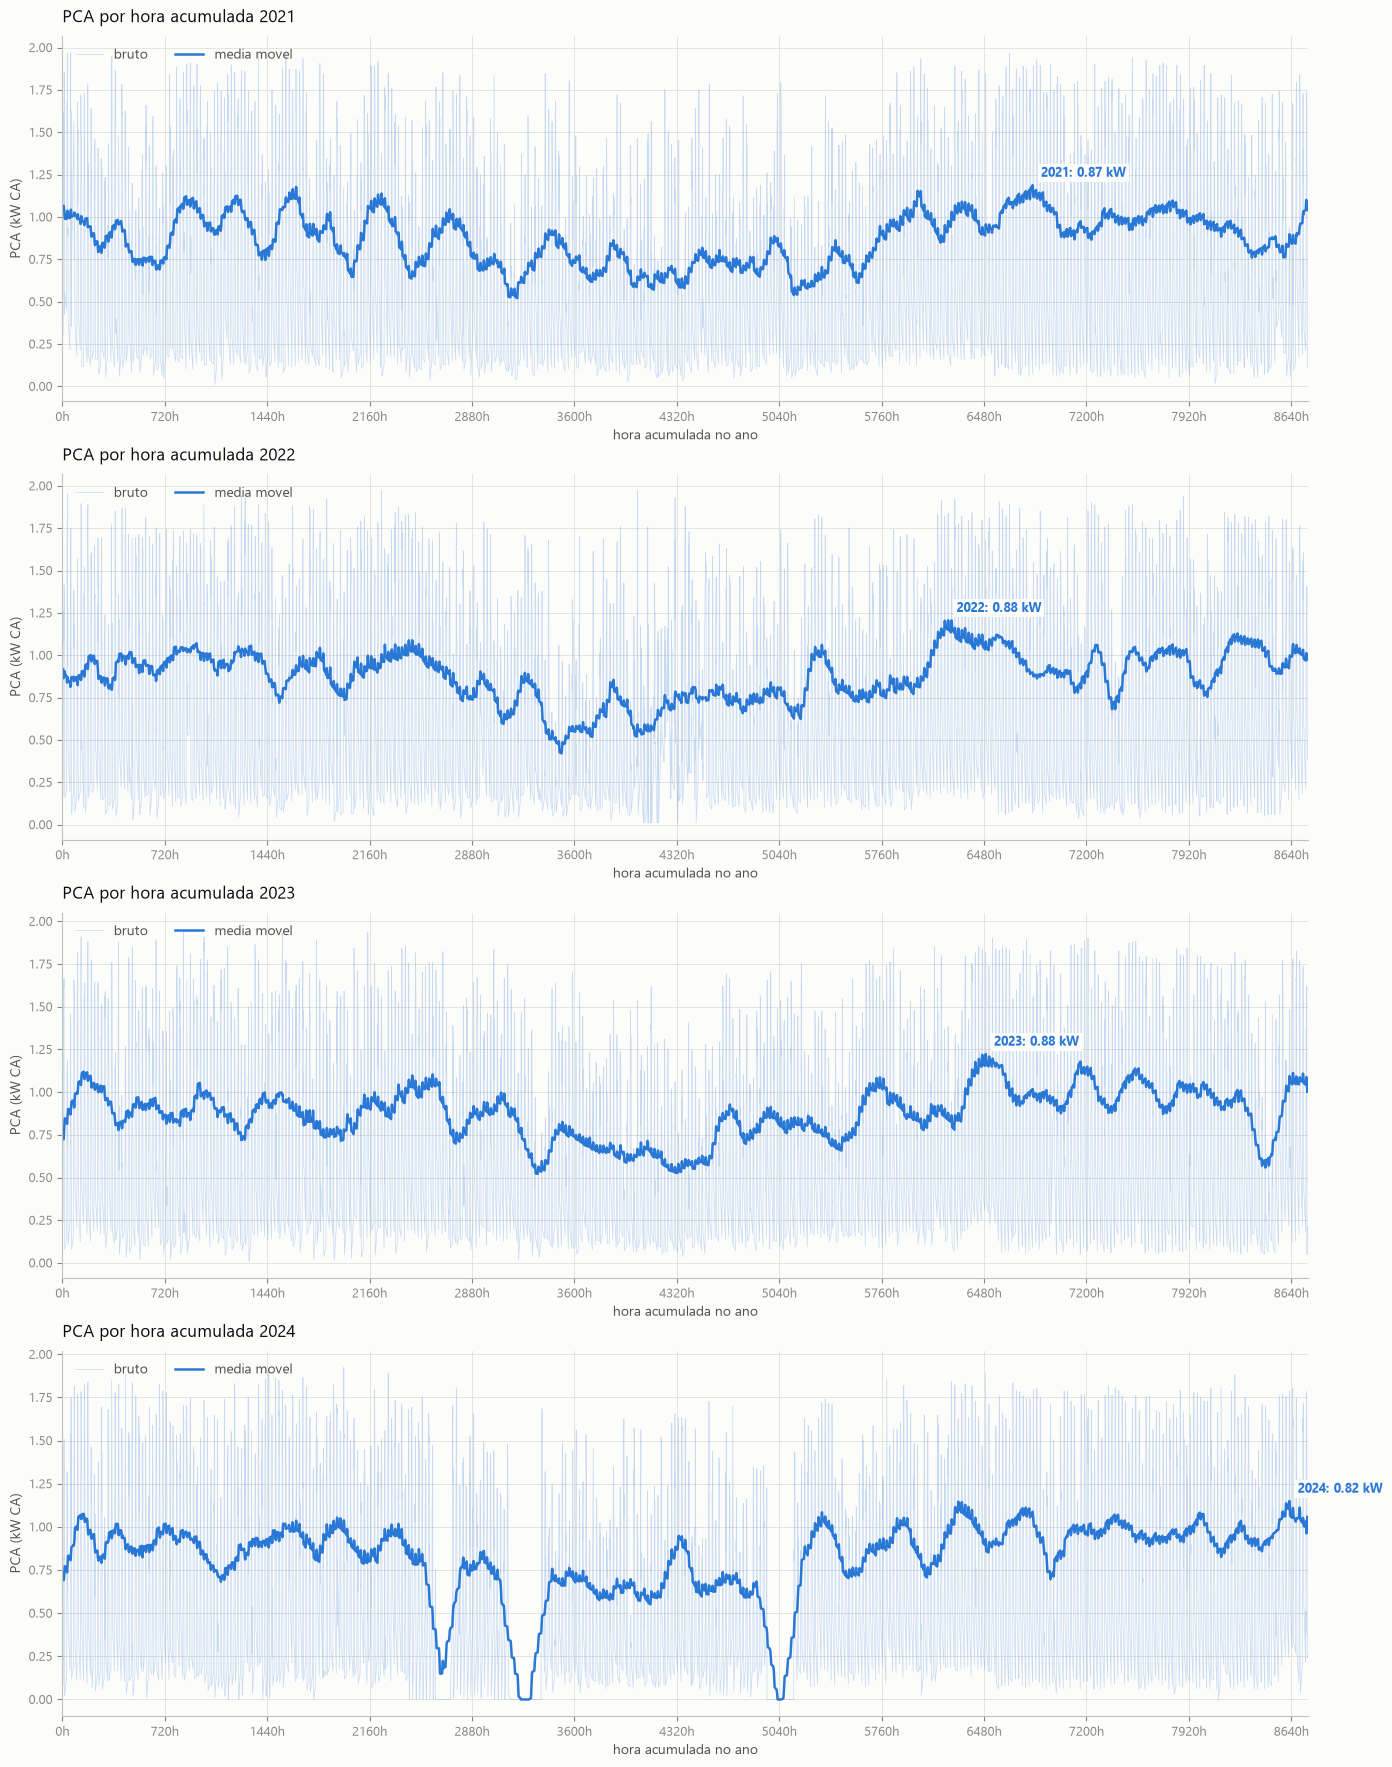

In [29]:

def plot_time_series(dataset):
    df_eval = dataset.copy()
    df_eval = df_eval.reset_index().drop(columns=[c for c in df_eval.columns if c not in ("PCA", "datetime")])

    # --- Comparacao sazonal do PCA: start vs end --------------------------------
    # df_eval tem somente index / datetime / PCA (start-end).
    df_eval["ano"]  = df_eval["datetime"].dt.year
    df_eval["mes"]  = df_eval["datetime"].dt.month
    df_eval["doy"]  = df_eval["datetime"].dt.dayofyear
    df_eval.loc[df_eval["doy"] == 366, "doy"] = 365
    df_eval["hora"] = df_eval["datetime"].dt.hour
    # hora acumulada no ano: hora 0 do dia 1 = 0, ...  (doy-1)*24 + hora
    df_eval["hora_ano"] = (df_eval["doy"] - 1) * 24 + df_eval["hora"]

   
    HALO = dict(facecolor=SUPERFICIE, edgecolor="none", pad=2.0)


    # --- 1. curva horaria acumulada ao longo do ano ----------------------------
    # x = hora acumulada no ano (0 .. 8760 h)
    # valor bruto (linha fina) + media movel de 1 semana (linha grossa).
    cor = REAL
    years = df_eval.datetime.dt.year.unique()
    fig, ax = plt.subplots(nrows=len(years),figsize=(14, 21))
    
    for i, ano in enumerate(years):
        d = df_eval[df_eval["ano"] == ano].sort_values("hora_ano").copy()
        # valor bruto
        ax[i].plot(d["hora_ano"], d["PCA"], color=cor, lw=0.5, alpha=0.25, label="bruto")
        # media movel
        JANELA = 1 + len(d) // 60
        mm = d["PCA"].rolling(window=JANELA, center=True, min_periods=1).mean()
        ax[i].plot(d["hora_ano"], mm, color=cor, lw=1.8, label="media movel")
        imax = mm.idxmax()
        ax[i].annotate(f"{ano}: {d['PCA'].mean():.2f} kW",
                    (d["hora_ano"].loc[imax], mm.loc[imax]),
                    xytext=(6, 6), textcoords="offset points",
                    color=cor, fontsize=9, fontweight="bold", bbox=HALO)
        enfeitar(ax[i], f"PCA por hora acumulada {ano}", "hora acumulada no ano", "PCA (kW CA)")
        ax[i].set_xlim(0, 365 * 24)
        ticks = np.arange(0, 365 * 24 + 1, 24 * 30)   # ~a cada 30 dias
        ax[i].set_xticks(ticks)
        ax[i].set_xticklabels([f"{int(t)}h" for t in ticks])
        ax[i].legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2, ncol=2)

    fig.subplots_adjust(top=0.87, bottom=0.07, left=0.07, right=0.96)
    plt.show()

plot_time_series(df)
